# Auto-prompt, one step at a time

No GPU needed for these steps. Use a **val** tile to judge and adjust methods, so decisions aren't tuned on the test strip.

## Step 1: Does ground removal work?

Automatic clicks are chosen from the lowest points, so anything left on the ground can attract them. CSF is the ground filter, and the true labels sort each point into three classes:

- **Blue, removed as ground:** a clean result has blue along the whole ground line.
- **Orange, kept but not a tree:** a band of orange along the bottom means ground was missed. Orange shapes standing above it are low plants or understory that isn't labelled as a tree.
- **Grey, kept tree:** blue on a trunk base would mean CSF removed part of a real tree.

In [1]:
import os
import sys

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")

import json

import numpy as np

from treeseg.data.ground import classify, csf_ground_mask, load_tile, plot_3d, plot_slice, summary

TILE_DIR = "data/wytham_isprs/tiles"
TILE = "isprs_val_t00_01"  # try isprs_val_t00_00 or isprs_val_t00_02 too

xyz, ids = load_tile(TILE_DIR, TILE)
print(f"{TILE}: {len(xyz):,} points, x {np.ptp(xyz[:, 0]):.0f} m, y {np.ptp(xyz[:, 1]):.0f} m")

isprs_val_t00_01: 3,672,493 points, x 27 m, y 30 m


### Run CSF

These are the settings Kevin's benchmark uses. Change them here to see the effect.

In [2]:
# CSF_SETTINGS = {"resolution": 2.0, "threshold": 0.5, "iterations": 500}

# CSF_SETTINGS = {"resolution": 2.0, "threshold": 0.5, "iterations": 500, "rigidness": 3}   # Kevin's
# CSF_SETTINGS = {"resolution": 1.0, "threshold": 0.5, "iterations": 500, "rigidness": 1}
CSF_SETTINGS = {"resolution": 0.5, "threshold": 0.5, "iterations": 500, "rigidness": 1}   # my pick
# CSF_SETTINGS = {"resolution": 0.25, "threshold": 0.5, "iterations": 500, "rigidness": 1}

ground = csf_ground_mask(xyz, **CSF_SETTINGS)
classes = classify(ground, ids)
print(json.dumps(summary(xyz, ids, classes), indent=2))

[0] Configuring terrain...
[0]  - bbMin: 28.05 -22.53 135.48
[0]  - bbMax: 55.17 18.12 165.48
[0] Configuring cloth...
[0]  - width: 58 height: 64
[0] Rasterizing...
[0] Simulating...
[0]  - post handle...
{
  "points": 3672493,
  "removed_as_ground": 0.1669168600185215,
  "labelled_not_tree": 0.3156618678374608,
  "kept_not_tree_share_of_kept": 0.18054827402719145,
  "kept_not_tree_by_height": {
    "0-0.3 m": 3.620656569862379e-06,
    "0.3-1 m": 0.031756778774262924,
    "1-3 m": 0.19737104126462293,
    "3-8 m": 0.6665990810773625,
    "8-99 m": 0.10426947822718172
  }
}


### Look at a slice

Change `SLICE_Y` to move through the tile. Check several, since one slice can mislead.

y runs from 135.5 to 165.5


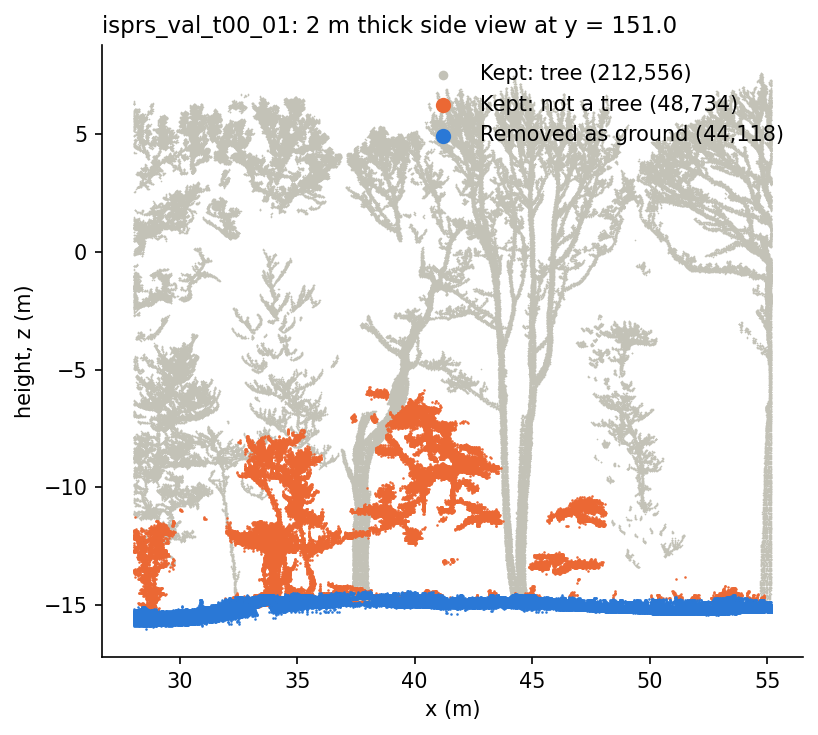

In [3]:
SLICE_Y = float(np.median(xyz[:, 1]))  # or a number within the range below
print(f"y runs from {xyz[:, 1].min():.1f} to {xyz[:, 1].max():.1f}")
plot_slice(xyz, classes, TILE, y=SLICE_Y);

### Rotate it in 3D

Drag to rotate and scroll to zoom. Click a legend entry to hide that class: hide the grey to see only what CSF removed and missed. This is a 150,000-point sample.

In [4]:
plot_3d(xyz, classes, TILE)

### Your call

Is the ground being removed? Write down what you see for each tile before changing anything:

- Is there a continuous orange band along the ground?
- Is any blue on trunks or tree parts?
- Do the orange shapes above the ground look like plants that should be background, or like trees missing a label?

## Step 2: Where do the automatic clicks land?

These two methods choose clicks with no labels. The labels are only used here to check them.

- **Grid:** the lowest 15% of points in the tile, cut into 4 m squares, one click at each square's median.
- **Stems:** a slice 0.3-2.5 m above the ground, with narrow vertical clusters treated as trunks. It clicks about 1.3 m up each one, and about 4 m up if it can.

This uses the ground removal from Step 1. Hide the points in the 3D view's legend to see the clicks alone, and look for clicks in empty air or on the ground.

In [ ]:
from treeseg.engine.clicks import BaseSurface, detect_stems, grid_clicks, stem_clicks
from treeseg.engine.scoring import click_quality, tree_sizes
from treeseg.utils.view3d import plot_click_map, plot_clicks_3d, plot_stem_steps

sizes = tree_sizes(ids)
work_xyz, work_ids = xyz[~ground], ids[~ground]
clicks = {"grid": grid_clicks(work_xyz), "stems": stem_clicks(work_xyz)}
for method, groups in clicks.items():
    print(method, click_quality(work_xyz, work_ids, groups, sizes))

In [ ]:
plot_clicks_3d(work_xyz, work_ids, clicks["stems"], f"{TILE}: stem clicks")

In [ ]:
plot_clicks_3d(work_xyz, work_ids, clicks["grid"], f"{TILE}: grid clicks")

## Step 3: Which trees get a click?

A view from above. Each circle is a labelled tree's base: green has a click on it somewhere, red has none. Diamonds are clicks on a tree, crosses are misses. The faint grid on the left is the 4 m squares.

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 7.5), dpi=120)
plot_click_map(work_xyz, work_ids, clicks["grid"], "Grid clicks", spacing=4.0, ax=axes[0])
plot_click_map(work_xyz, work_ids, clicks["stems"], "Stem clicks", ax=axes[1])
fig.tight_layout();

## Step 4: One trunk, step by step

The stem finder's view of one detection. Blue is the height slice it searched, and the diamonds are the clicks it chose. Change `STEM` to look at others. Does this look like a trunk, and is the click on it?

In [ ]:
STEM = 0

stems = detect_stems(work_xyz)
height = BaseSurface(work_xyz).height(work_xyz)
print(f"{len(stems)} trunks detected")
plot_stem_steps(work_xyz, height, stems[STEM], title=f"{TILE}: detection {STEM}, {stems[STEM]['size']} points in its cluster");

## Next: what mask does a click give?

Clicks are only half of it. Seeing the mask each click produces needs a GPU, so it's in `03_benchmark.ipynb`, which shows true and predicted trees side by side.